# Credit Card Default Prediction with Logistic Regression

**Business context.** A card issuer wants an **early-warning model**: which cardholders are likely to miss next month's payment?
Accounts flagged early can get a reminder call, a payment plan, or a credit-limit review before the loss happens.
The model's output is a **probability of default (PD)** for each account, plus a **scorecard**: points that add up to a credit score,
the format risk teams and regulators expect.

**Why logistic regression?** In regulated banking, a model has to be explained to validators, auditors and regulators.
Logistic regression gives a probability directly, each feature's effect can be read from one coefficient, and it converts into
a points-based scorecard. Section 13 compares it with a more complex "challenger" model to show what that transparency costs.

**Dataset.** *Default of Credit Card Clients* (UCI Machine Learning Repository, Yeh & Lien, 2009):
30,000 credit card holders at a bank in Taiwan, with six months of history (April to September 2005) and whether they defaulted in October.
Amounts are in **New Taiwan dollars (NT\$)**.

**Outline**
1. Setup and data loading
2. Data dictionary and data-quality checks
3. Fair lending: which columns the model must not use
4. Feature engineering
5. Train/test split
6. Binning, weight of evidence (WoE) and information value (IV)
7. Logistic regression with `statsmodels`: feature selection and coefficients
8. Class imbalance: why the model is not re-weighted
9. Performance: AUC, Gini and KS, calculated step by step
10. Calibration: do predicted PDs match reality?
11. Choosing a cut-off from business costs
12. The scorecard: turning PD into points
13. Challenger models
14. Fairness check
15. Monitoring: population stability index (PSI)
16. Limitations and model ownership

> **How to read this notebook:** each section starts with *what* the step does and *why*.
> Code cells have inline comments (lines starting with `#`) explaining each line.

## 1. Setup and data loading

| Library | Used for |
|---|---|
| `pandas`, `numpy` | Data tables and maths |
| `matplotlib` | Charts |
| `statsmodels` | Logistic regression with p-values and confidence intervals; VIF |
| `scikit-learn` | Train/test split, cross-validation, logistic regression in a pipeline, metrics, challenger models |

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, confusion_matrix

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RANDOM_STATE = 42                     # fixed seed: same split and folds on every run
TARGET = "default_next_month"
FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

In [2]:
DATA_DIR = "../data"
CSV_PATH = os.path.join(DATA_DIR, "credit_card_default.csv")
# Fallback copy of the original UCI file (used only if the CSV isn't in data/)
URL = ("https://raw.githubusercontent.com/MatteoM95/Default-of-Credit-Card-Clients-Dataset-Analisys/"
       "main/dataset/default_of_credit_card_clients.csv")

if not os.path.exists(CSV_PATH):
    os.makedirs(DATA_DIR, exist_ok=True)
    pd.read_csv(URL).rename(columns={"default payment next month": TARGET}).to_csv(CSV_PATH, index=False)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 2. Data dictionary and data-quality checks

| Column | Meaning |
|---|---|
| `LIMIT_BAL` | Credit limit (NT\$), covering the individual and any supplementary cards |
| `SEX`, `EDUCATION`, `MARRIAGE`, `AGE` | Demographics (see Section 3: not used by the model) |
| `PAY_0`, `PAY_2` … `PAY_6` | Repayment status in Sep, Aug, Jul, Jun, May, Apr (there is no `PAY_1`) |
| `BILL_AMT1` … `BILL_AMT6` | Statement balance (NT\$), Sep back to Apr |
| `PAY_AMT1` … `PAY_AMT6` | Amount paid (NT\$), Sep back to Apr |
| `default_next_month` | **Target**: 1 = defaulted in October 2005 |

**Repayment status codes.** The original documentation lists −1 = paid duly and 1–9 = months of delay.
The data also contains **−2** and **0**, which are widely interpreted as −2 = no card use that month and 0 = revolving credit (minimum paid, balance carried).
This notebook uses that interpretation, and states it as an assumption.

In [3]:
# Missing values and duplicates
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs: ", df["ID"].duplicated().sum())

# Target: what share of accounts defaulted?
print(f"\nDefault rate: {df[TARGET].mean():.2%}  ({df[TARGET].sum():,} of {len(df):,})")

# Codes outside the documentation
print("\nEDUCATION codes:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE codes: ", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_0 codes:    ", df["PAY_0"].value_counts().sort_index().to_dict())

# Negative statement balances = the customer has a credit balance (overpaid)
print(f"\nAccounts with a negative September balance: {(df['BILL_AMT1'] < 0).sum():,}")

Missing values: 0
Duplicate IDs:  0

Default rate: 22.12%  (6,636 of 30,000)

EDUCATION codes: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE codes:  {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0 codes:     {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}

Accounts with a negative September balance: 590


**Data-quality findings**

| Issue | Detail | Decision |
|---|---|---|
| Missing / duplicate rows | None | No action |
| Target balance | 22.1% default, so 3.5 good accounts per bad one | Stratify the split; handle in the cut-off, not by re-weighting (Section 8) |
| `EDUCATION` codes 0, 5, 6 | Undocumented (465 rows) | Not used (Section 3) |
| `MARRIAGE` code 0 | Undocumented (54 rows) | Not used (Section 3) |
| `PAY_x` codes −2 and 0 | Undocumented, interpreted as no use / revolving | Kept as their own categories, an assumption a validator should confirm |
| Negative balances | Credit balances (overpayment) | Kept; they are real states, not errors |

## 3. Fair lending: which columns the model must not use

The **Canadian Human Rights Act** prohibits discrimination on grounds that include **sex, marital status and age**.
A credit model that uses them can produce discriminatory outcomes, so they are left out:

| Column | Decision | Reason |
|---|---|---|
| `SEX` | Excluded | Protected ground |
| `MARRIAGE` | Excluded | Protected ground (marital status) |
| `AGE` | Excluded | Protected ground |
| `EDUCATION` | Excluded | Undocumented codes, and education can act as a *proxy* for protected characteristics |

Removing a column doesn't guarantee fair outcomes, because other features can be correlated with it.
That is why Section 14 checks the finished model's results by sex and age group.

In [4]:
EXCLUDED = ["SEX", "MARRIAGE", "AGE", "EDUCATION"]
print("Columns the model will never see:", EXCLUDED)

Columns the model will never see: ['SEX', 'MARRIAGE', 'AGE', 'EDUCATION']


## 4. Feature engineering

**What this does:** turns six months of raw history into a few behavioural features a credit-risk analyst would recognise.

| Feature | Formula | Meaning |
|---|---|---|
| `limit_bal` | `LIMIT_BAL` | Credit limit; the bank's own earlier view of the customer's capacity |
| `pay_status_latest` | `PAY_0` | Repayment status in September, the most recent month |
| `months_delinquent_6m` | count of `PAY_x` ≥ 1 | How many of the last 6 months had a late payment |
| `avg_utilization_6m` | mean(`BILL_AMT1..6`) ÷ `LIMIT_BAL` | Average balance as a share of the limit |
| `payment_ratio_5m` | sum(`PAY_AMT1..5`) ÷ sum(`BILL_AMT2..6`) | Share of each bill actually paid (candidate; tested in Section 7) |

**Aligning payments with bills.** `PAY_AMT1` is the amount paid in *September*, which pays the *August* statement (`BILL_AMT2`).
So the payment ratio pairs `PAY_AMT1..5` with `BILL_AMT2..6`, not with the same month's bill.

In [5]:
PAY_COLS = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
BILL_COLS = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMT_COLS = [f"PAY_AMT{i}" for i in range(1, 7)]

feat = pd.DataFrame(index=df.index)
feat["limit_bal"] = df["LIMIT_BAL"]
feat["pay_status_latest"] = df["PAY_0"]
feat["months_delinquent_6m"] = (df[PAY_COLS] >= 1).sum(axis=1)            # months with any delay
feat["avg_utilization_6m"] = df[BILL_COLS].mean(axis=1) / df["LIMIT_BAL"]

owed = df[BILL_COLS[1:]].clip(lower=0).sum(axis=1)                        # Aug..Apr bills (ignore credit balances)
paid = df[PAY_AMT_COLS[:5]].sum(axis=1)                                    # paid Sep..May
feat["payment_ratio_5m"] = (paid / owed.replace(0, np.nan)).fillna(1.0).clip(0, 2)  # nothing owed -> fully paid; cap at 200%

data = pd.concat([df, feat], axis=1)
feat.describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
limit_bal,"30,000.000","167,484.323","129,747.662","10,000.000","10,000.000","140,000.000","500,000.000","1,000,000.000"
pay_status_latest,"30,000.000",-0.017,1.124,-2.000,-2.000,0.000,3.000,8.000
months_delinquent_6m,"30,000.000",0.834,1.554,0.000,0.000,0.000,6.000,6.000
avg_utilization_6m,"30,000.000",0.373,0.352,-0.233,0.000,0.285,1.048,5.364
payment_ratio_5m,"30,000.000",0.397,0.430,0.000,0.015,0.123,1.333,2.000


## 5. Train/test split

**What this does:** holds back 20% of accounts as a test set, untouched until Section 9.
`stratify` keeps the 22.1% default rate identical in both parts, so neither gets an easier or harder mix.

In [6]:
train, test = train_test_split(data, test_size=0.2, stratify=data[TARGET], random_state=RANDOM_STATE)
y_train, y_test = train[TARGET], test[TARGET]
print(f"Train: {len(train):,} accounts, default rate {y_train.mean():.2%}")
print(f"Test:  {len(test):,} accounts, default rate {y_test.mean():.2%}")

Train: 24,000 accounts, default rate 22.12%
Test:  6,000 accounts, default rate 22.12%


## 6. Binning, weight of evidence (WoE) and information value (IV)

This is the standard way credit scorecards prepare features.

**Step 1, binning.** Each feature is cut into a few groups (bins). Continuous features use training-set quantiles, rounded to readable values.

**Step 2, weight of evidence.** For each bin *i*:

$$WoE_i = \ln\left(\frac{\text{share of all good accounts that fall in bin } i}{\text{share of all bad accounts that fall in bin } i}\right)$$

- WoE > 0: the bin holds relatively more good accounts (safer than average)
- WoE < 0: relatively more bad accounts (riskier)

The model then uses each account's bin WoE instead of the raw value. This has three advantages:
- It handles **non-linear patterns** (a U-shape, say) that a plain logistic regression would miss.
- Outliers can't distort the model: an extreme value just lands in the outer bin.
- WoE is on the log-odds scale, which is exactly what logistic regression models.

**Step 3, information value** measures a feature's overall predictive strength:

$$IV = \sum_i (\text{good share}_i - \text{bad share}_i) \times WoE_i$$

| IV | Strength |
|---|---|
| < 0.02 | Not useful |
| 0.02–0.1 | Weak |
| 0.1–0.3 | Medium |
| > 0.3 | Strong (above 0.5, check it isn't leaking the answer) |

In [7]:
# First look at the continuous features' training-set quintiles (the basis for the bin edges)
for col in ["limit_bal", "avg_utilization_6m", "payment_ratio_5m"]:
    print(col, np.round(train[col].quantile([0.2, 0.4, 0.6, 0.8]).values, 3))

limit_bal [ 50000. 100000. 180000. 270000.]
avg_utilization_6m [0.018 0.132 0.451 0.756]
payment_ratio_5m [0.043 0.071 0.314 1.   ]


In [8]:
# Bin edges: the quintiles above, rounded. Each bin is (lower, upper].
BIN_EDGES = {
    "limit_bal": [-np.inf, 50_000, 100_000, 180_000, 270_000, np.inf],
    # -2, -1 and 0 are different behaviours, not degrees of lateness, so each keeps its own bin
    "pay_status_latest": [-np.inf, -2, -1, 0, 1, 2, np.inf],
    "months_delinquent_6m": [-np.inf, 0, 1, 2, np.inf],
    "avg_utilization_6m": [-np.inf, 0.02, 0.13, 0.45, 0.75, np.inf],
    "payment_ratio_5m": [-np.inf, 0.04, 0.07, 0.30, 1.0, np.inf],
}
BIN_LABELS = {
    "limit_bal": ["≤ NT$50K", "NT$50K–100K", "NT$100K–180K", "NT$180K–270K", "> NT$270K"],
    "pay_status_latest": ["No card use", "Paid in full", "Revolving (paid minimum)",
                          "1 month late", "2 months late", "3+ months late"],
    "months_delinquent_6m": ["0", "1", "2", "3 or more"],
    "avg_utilization_6m": ["≤ 2% (inactive)", "2%–13%", "13%–45%", "45%–75%", "> 75%"],
    "payment_ratio_5m": ["≤ 4%", "4%–7%", "7%–30%", "30%–100%", "> 100%"],
}
CANDIDATES = list(BIN_EDGES)


def assign_bins(feature, values):
    # Map each raw value to its bin number 0, 1, 2, ...
    return pd.cut(values, bins=BIN_EDGES[feature], labels=False, right=True).astype(int)


def woe_table(feature, x, y):
    # WoE and IV for every bin of one feature. 0.5 is added to each count (smoothing)
    # so that a bin with no bad (or no good) accounts can't produce ln(0).
    bins = assign_bins(feature, x).values
    y = np.asarray(y)
    n_bins = len(BIN_EDGES[feature]) - 1
    total_bad, total_good = y.sum(), (1 - y).sum()
    rows = []
    for b in range(n_bins):
        in_bin = bins == b
        bad, good = y[in_bin].sum(), (1 - y[in_bin]).sum()
        pct_good = (good + 0.5) / (total_good + 0.5 * n_bins)
        pct_bad = (bad + 0.5) / (total_bad + 0.5 * n_bins)
        woe = np.log(pct_good / pct_bad)
        rows.append({"bin": BIN_LABELS[feature][b], "accounts": int(in_bin.sum()), "defaults": int(bad),
                     "default_rate": bad / max(in_bin.sum(), 1), "pct_good": pct_good, "pct_bad": pct_bad,
                     "woe": woe, "iv": (pct_good - pct_bad) * woe})
    return pd.DataFrame(rows)


tables = {f: woe_table(f, train[f], y_train) for f in CANDIDATES}
tables["pay_status_latest"]

,bin,accounts,defaults,default_rate,pct_good,pct_bad,woe,iv
0,No card use,2198,279,0.127,0.103,0.053,0.669,0.033
1,Paid in full,4527,753,0.166,0.202,0.142,0.353,0.021
2,Revolving (paid minimum),11781,1508,0.128,0.550,0.284,0.660,0.175
3,1 month late,3000,1031,0.344,0.105,0.194,-0.611,0.054
4,2 months late,2138,1483,0.694,0.035,0.279,-2.075,0.507
5,3+ months late,356,255,0.716,0.005,0.048,-2.181,0.093


**One bin by hand.** Take *2 months late* in the table above. Using the training counts printed below:

In [9]:
t = tables["pay_status_latest"]
row = t[t["bin"] == "2 months late"].iloc[0]
total_bad, total_good = y_train.sum(), (1 - y_train).sum()
bad, good = row["defaults"], row["accounts"] - row["defaults"]

print(f"Accounts in bin: {row['accounts']:,}   bad: {bad:,}   good: {good:,}")
print(f"All training accounts:   bad: {total_bad:,}   good: {total_good:,}")
pg = (good + 0.5) / (total_good + 0.5 * 6)       # 6 bins for this feature
pb = (bad + 0.5) / (total_bad + 0.5 * 6)
print(f"Share of all goods in this bin = ({good} + 0.5) / ({total_good} + 3) = {pg:.4f}")
print(f"Share of all bads in this bin  = ({bad} + 0.5) / ({total_bad} + 3) = {pb:.4f}")
print(f"WoE = ln({pg:.4f} / {pb:.4f}) = {np.log(pg / pb):.3f}   (strongly negative: a very risky bin)")
print(f"IV contribution = ({pg:.4f} - {pb:.4f}) x {np.log(pg / pb):.3f} = {(pg - pb) * np.log(pg / pb):.4f}")

Accounts in bin: 2,138   bad: 1,483   good: 655
All training accounts:   bad: 5,309   good: 18,691
Share of all goods in this bin = (655 + 0.5) / (18691 + 3) = 0.0351
Share of all bads in this bin  = (1483 + 0.5) / (5309 + 3) = 0.2793
WoE = ln(0.0351 / 0.2793) = -2.075   (strongly negative: a very risky bin)
IV contribution = (0.0351 - 0.2793) x -2.075 = 0.5067


In [10]:
# Information value of each candidate feature
iv = pd.Series({f: t["iv"].sum() for f, t in tables.items()}).sort_values(ascending=False)
iv.to_frame("information_value")

,information_value
pay_status_latest,0.884
months_delinquent_6m,0.857
limit_bal,0.171
payment_ratio_5m,0.123
avg_utilization_6m,0.115


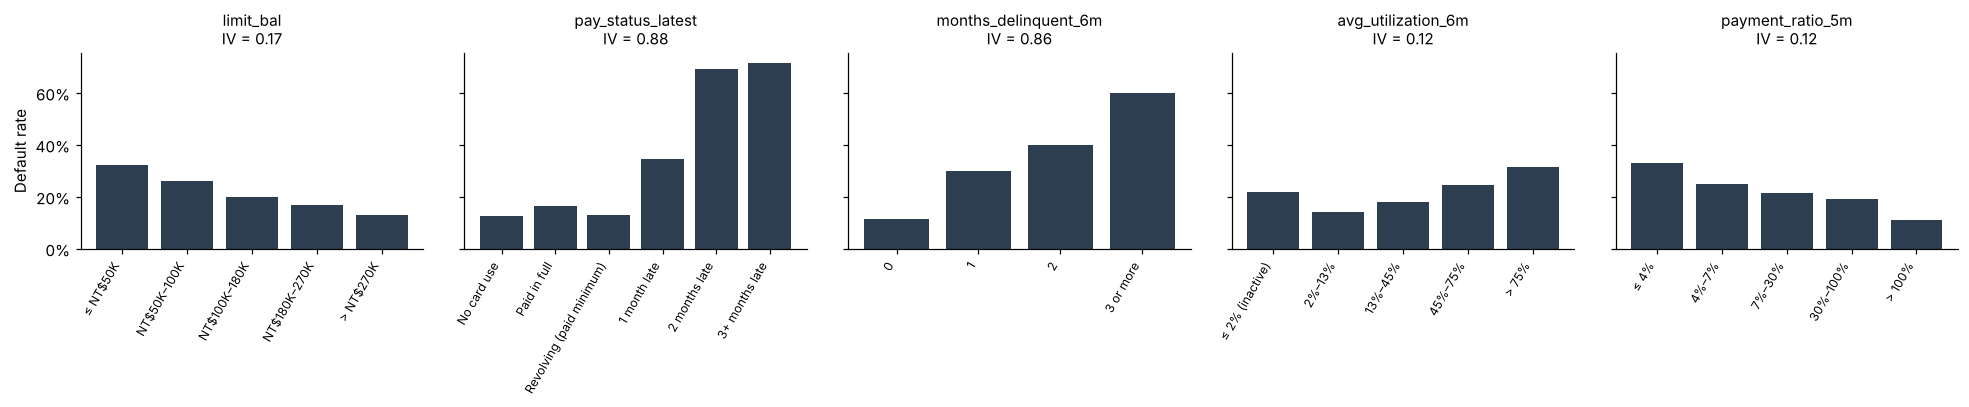

In [11]:
# Default rate by bin for each feature (the shape that WoE captures)
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8), sharey=True)
for ax, f in zip(axes, CANDIDATES):
    t = tables[f]
    ax.bar(range(len(t)), t["default_rate"], color="#2C3E50")
    ax.set_xticks(range(len(t)), t["bin"], rotation=60, ha="right", fontsize=8)
    ax.set_title(f"{f}\nIV = {iv[f]:.2f}", fontsize=10)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Default rate")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/01_default_rate_by_bin.png", dpi=120, bbox_inches="tight"); plt.show()

**What the bins show**
- **Repayment history dominates** (IV 0.88 and 0.86). That is expected for a *behavioural* model, which scores existing customers on how they have been paying.
  It isn't leakage: the history covers April–September and the target is October.
- **Latest repayment status:** "paid in full" (16.6%) is slightly riskier than "revolving" (12.8%). Merging those groups into one "current" bin
  would hide that, and costs predictive power (tested in the next cell). Since they are different behaviours rather than degrees of lateness, they keep separate bins.
- **Utilization has a U-shape:** completely inactive cards (≤ 2% used) default more than lightly used ones, then risk rises again with heavy use.
  A plain logistic regression on raw utilization can only draw a straight line; WoE captures the U.
- **Credit limit:** lower limits default more (the bank already judged these customers riskier).

In [12]:
# Does keeping "no use / paid in full / revolving" separate actually help? Compare cross-validated AUC.
def cv_auc_for_pay_bins(edges):
    old = BIN_EDGES["pay_status_latest"]
    BIN_EDGES["pay_status_latest"] = edges
    x = pd.DataFrame({f: woe_table(f, train[f], y_train)["woe"].values[assign_bins(f, train[f]).values]
                      for f in ["pay_status_latest", "months_delinquent_6m", "limit_bal", "avg_utilization_6m"]})
    BIN_EDGES["pay_status_latest"] = old
    # (WoE here is learned on all of train, which is fine for a like-for-like comparison of binning choices)
    return cross_val_score(LogisticRegression(max_iter=1000), x, y_train, cv=5, scoring="roc_auc").mean()

print(f"Merged 'current' bin  (-2, -1, 0 together): AUC = {cv_auc_for_pay_bins([-np.inf, 0, 1, 2, np.inf]):.4f}")
print(f"Separate bins         (-2 | -1 | 0):        AUC = {cv_auc_for_pay_bins(BIN_EDGES['pay_status_latest']):.4f}")

Merged 'current' bin  (-2, -1, 0 together): AUC = 0.7613
Separate bins         (-2 | -1 | 0):        AUC = 0.7650


## 7. Logistic regression with `statsmodels`: feature selection and coefficients

**What this does:** replaces each feature with its WoE value and fits a logistic regression:

$$\ln\left(\frac{PD}{1 - PD}\right) = \beta_0 + \beta_1 WoE_1 + \dots + \beta_k WoE_k$$

Because WoE is defined as ln(good/bad), a higher WoE means *safer*, so every coefficient should be **negative**
(more WoE → lower log-odds of default). A positive or near-zero coefficient is a warning sign.

**Feature selection.** IV ranks features one at a time. A feature can have a decent IV yet add nothing once correlated features are
in the model. I start with all five candidates and check each one's contribution.

In [13]:
def woe_transform(frame, features, tables):
    # Replace raw values with the WoE of their bin (WoE tables learned on TRAIN only)
    return pd.DataFrame({f: tables[f]["woe"].values[assign_bins(f, frame[f]).values] for f in features},
                        index=frame.index)

W_train_all = woe_transform(train, CANDIDATES, tables)
logit_all = sm.Logit(y_train, sm.add_constant(W_train_all)).fit(disp=0)
print(logit_all.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].round(4))

                      Coef.  Std.Err.  P>|z|
const                -1.252     0.018  0.000
limit_bal            -0.451     0.045  0.000
pay_status_latest    -0.599     0.025  0.000
months_delinquent_6m -0.484     0.026  0.000
avg_utilization_6m   -0.339     0.059  0.000
payment_ratio_5m     -0.068     0.057  0.235


In [14]:
# Why does payment ratio add so little? It overlaps with the delinquency features.
print(W_train_all.corr().round(2))

                      limit_bal  pay_status_latest  months_delinquent_6m  \
limit_bal                 1.000              0.170                 0.260   
pay_status_latest         0.170              1.000                 0.750   
months_delinquent_6m      0.260              0.750                 1.000   
avg_utilization_6m        0.290              0.150                 0.190   
payment_ratio_5m          0.220              0.170                 0.250   

                      avg_utilization_6m  payment_ratio_5m  
limit_bal                          0.290             0.220  
pay_status_latest                  0.150             0.170  
months_delinquent_6m               0.190             0.250  
avg_utilization_6m                 1.000             0.450  
payment_ratio_5m                   0.450             1.000  


**Decision: drop `payment_ratio_5m`.** Its coefficient is close to zero and its p-value is far above 0.05:
customers who pay a small share of their bills are largely the same customers who show up as late or revolving in the repayment status.
Its medium IV (0.12) on its own doesn't survive in a model with the delinquency features. Fewer features also means a simpler scorecard to validate and monitor.

In [15]:
FEATURES = ["limit_bal", "pay_status_latest", "months_delinquent_6m", "avg_utilization_6m"]
W_train = woe_transform(train, FEATURES, tables)
W_test = woe_transform(test, FEATURES, tables)

logit = sm.Logit(y_train, sm.add_constant(W_train)).fit(disp=0)
print(logit.summary2())

                           Results: Logit
Model:                Logit              Method:           MLE       
Dependent Variable:   default_next_month Pseudo R-squared: 0.172     
Date:                 2026-11-14 22:15   AIC:              21010.9295
No. Observations:     24000              BIC:              21051.3586
Df Model:             4                  Log-Likelihood:   -10500.   
Df Residuals:         23995              LL-Null:          -12682.   
Converged:            1.0000             LLR p-value:      0.0000    
No. Iterations:       6.0000             Scale:            1.0000    
---------------------------------------------------------------------
                      Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------------
const                -1.2534   0.0176 -71.2044 0.0000 -1.2879 -1.2189
limit_bal            -0.4542   0.0447 -10.1498 0.0000 -0.5419 -0.3665
pay_status_latest    -0.5996   0.0246 -24.3899 0

In [16]:
# Multicollinearity check: variance inflation factor (VIF), as in project 1.
# VIF_j = 1 / (1 - R²_j), where R²_j comes from regressing feature j on the other features.
Xc = sm.add_constant(W_train)
pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(len(FEATURES))],
          index=FEATURES, name="VIF").round(2)

limit_bal              1.150
pay_status_latest      2.260
months_delinquent_6m   2.370
avg_utilization_6m     1.110
Name: VIF, dtype: float64

**Reading the result**
- **All four coefficients are negative**, as they should be, and all are highly significant.
- **VIFs are below 5**: the two delinquency features overlap (both count late payments), but not enough to make the coefficients unstable.
- **Interpreting a coefficient:** for latest repayment status (β ≈ −0.60), moving from *revolving* (WoE +0.66) to *2 months late* (WoE −2.08)
  changes the log-odds of default by −0.60 × (−2.08 − 0.66) = **+1.64**, which multiplies the odds of default by e^1.64 ≈ **5.2**, holding the other features fixed.
- The scikit-learn pipeline below fits the same model (with a negligible penalty, C = 10⁶), so its coefficients match these.

## 8. Class imbalance: why the model is not re-weighted

Only 22% of accounts default. A common reflex is `class_weight="balanced"`, which makes the model treat defaults as if they were 50% of the data.
For a **PD model** that is a mistake: ranking ability barely changes, but the probabilities stop meaning anything.

In [17]:
for weight in [None, "balanced"]:
    m = LogisticRegression(C=1e6, max_iter=1000, class_weight=weight).fit(W_train, y_train)
    p = m.predict_proba(W_test)[:, 1]
    print(f"class_weight={str(weight):9s}  AUC = {roc_auc_score(y_test, p):.4f}   "
          f"average predicted PD = {p.mean():.1%}   (actual default rate {y_test.mean():.1%})")

class_weight=None       AUC = 0.7438   average predicted PD = 22.0%   (actual default rate 22.1%)


class_weight=balanced   AUC = 0.7435   average predicted PD = 43.6%   (actual default rate 22.1%)


**Same AUC, wrong probabilities.** The re-weighted model says the average account has a 44% chance of default when the truth is 22%.
Any expected-loss, pricing or provisioning calculation built on that would be badly wrong.
The imbalance is handled where it belongs instead: in the **cut-off** (Section 11), which decides how many accounts to flag.

## 9. Performance: AUC, Gini and KS

**The pipeline.** The final model is a scikit-learn `Pipeline` (WoE encoder → logistic regression). Inside cross-validation,
the WoE tables are re-learned on each training fold, so the held-out fold's defaults never influence its own encoding.

**Metrics**
- **AUC**: the probability that a randomly chosen defaulter gets a higher PD than a randomly chosen non-defaulter. 0.5 = random, 1.0 = perfect.
- **Gini** = 2 × AUC − 1, the version most banks report. 0 = random, 1 = perfect.
- **KS** (Kolmogorov–Smirnov): sort accounts from riskiest to safest; KS is the largest gap between the cumulative share of bads and the cumulative share of goods captured.

In [18]:
class WoEEncoder(BaseEstimator, TransformerMixin):
    # scikit-learn wrapper around woe_table, so WoE can be re-learned inside each CV fold
    def fit(self, X, y):
        self.tables_ = {f: woe_table(f, X[f], y) for f in FEATURES}
        return self
    def transform(self, X):
        return woe_transform(X, FEATURES, self.tables_)

def make_scorecard():
    return Pipeline([("woe", WoEEncoder()), ("model", LogisticRegression(C=1e6, max_iter=1000))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc = cross_val_score(make_scorecard(), train[FEATURES], y_train, cv=cv, scoring="roc_auc")
print("5-fold CV AUC per fold:", np.round(cv_auc, 4))
print(f"Mean CV AUC = {cv_auc.mean():.4f} (std {cv_auc.std():.4f})")

scorecard = make_scorecard().fit(train[FEATURES], y_train)
pd_test = scorecard.predict_proba(test[FEATURES])[:, 1]
pd_train = scorecard.predict_proba(train[FEATURES])[:, 1]
print("\nPipeline coefficients (should match statsmodels):", np.round(scorecard.named_steps["model"].coef_[0], 3))

5-fold CV AUC per fold: [0.7684 0.7638 0.7514 0.761  0.7778]
Mean CV AUC = 0.7645 (std 0.0087)



Pipeline coefficients (should match statsmodels): [-0.454 -0.599 -0.489 -0.367]


In [19]:
# --- KS, step by step ---
order = np.argsort(-pd_test)                          # riskiest first
y_sorted = y_test.values[order]
cum_bad = np.cumsum(y_sorted) / y_sorted.sum()        # share of all bads found so far
cum_good = np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()
ks_index = np.argmax(cum_bad - cum_good)
ks = (cum_bad - cum_good)[ks_index]

auc = roc_auc_score(y_test, pd_test)
print(f"Test AUC  = {auc:.4f}")
print(f"Gini      = 2 x {auc:.4f} - 1 = {2 * auc - 1:.4f}")
print(f"KS        = {ks:.4f}: after reviewing the riskiest {(ks_index + 1) / len(y_sorted):.1%} of accounts, "
      f"we've found {cum_bad[ks_index]:.1%} of the defaulters but only {cum_good[ks_index]:.1%} of the good accounts")
print(f"Brier score = {brier_score_loss(y_test, pd_test):.4f}  (mean squared error of the PD; lower is better)")

Test AUC  = 0.7438
Gini      = 2 x 0.7438 - 1 = 0.4875
KS        = 0.3855: after reviewing the riskiest 24.1% of accounts, we've found 54.1% of the defaulters but only 15.6% of the good accounts
Brier score = 0.1408  (mean squared error of the PD; lower is better)


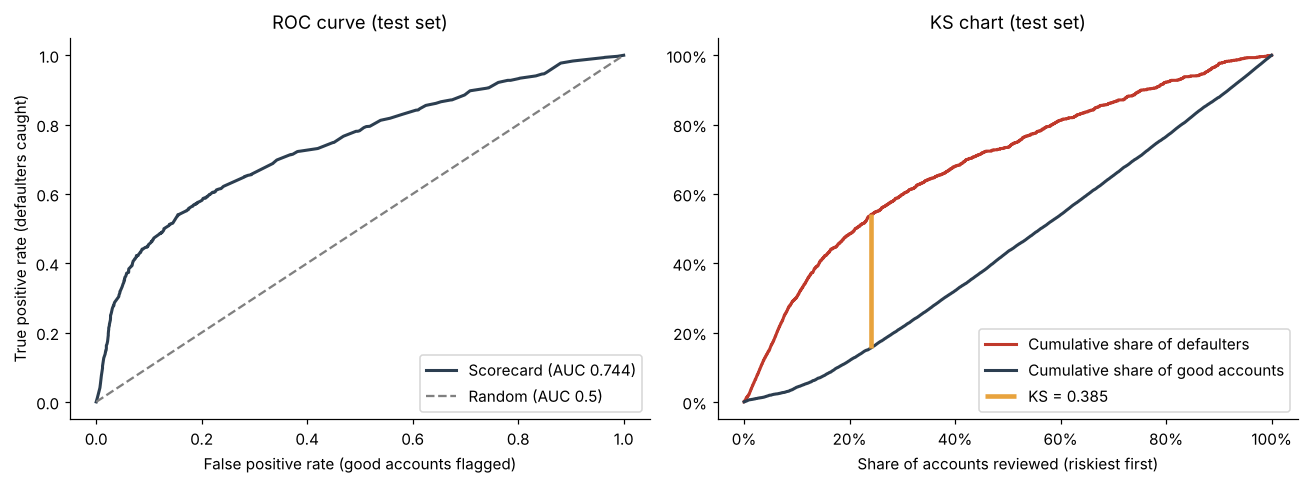

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_test, pd_test)
axes[0].plot(fpr, tpr, color="#2C3E50", lw=2, label=f"Scorecard (AUC {auc:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random (AUC 0.5)")
axes[0].set_xlabel("False positive rate (good accounts flagged)"); axes[0].set_ylabel("True positive rate (defaulters caught)")
axes[0].set_title("ROC curve (test set)"); axes[0].legend(loc="lower right")

share = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
axes[1].plot(share, cum_bad, color="#C0392B", lw=2, label="Cumulative share of defaulters")
axes[1].plot(share, cum_good, color="#2C3E50", lw=2, label="Cumulative share of good accounts")
axes[1].vlines(share[ks_index], cum_good[ks_index], cum_bad[ks_index], color="#E8A33D", lw=3, label=f"KS = {ks:.3f}")
axes[1].set_xlabel("Share of accounts reviewed (riskiest first)"); axes[1].set_title("KS chart (test set)")
axes[1].xaxis.set_major_formatter(PercentFormatter(1)); axes[1].yaxis.set_major_formatter(PercentFormatter(1)); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/02_roc_ks.png", dpi=120, bbox_inches="tight"); plt.show()

**Reading the numbers.** The test AUC (≈ 0.74) is a little below the cross-validated mean (≈ 0.76): this particular 20% test split is harder than average.
Both are reported, because a single split can be lucky or unlucky. A Gini near 0.5 and a KS near 0.39 are typical of a behavioural card model
built on a handful of features.

## 10. Calibration: do predicted PDs match reality?

AUC only measures *ranking*. A PD model must also be **calibrated**: among accounts given a 20% PD, about 20% should actually default.
The check: split test accounts into 10 equal groups (deciles) from riskiest to safest and compare the average predicted PD with the actual default rate.

In [21]:
d = pd.DataFrame({"y": y_test.values, "pd": pd_test})
d["decile"] = pd.qcut(d["pd"].rank(method="first", ascending=False), 10, labels=range(1, 11))
deciles = d.groupby("decile", observed=True).agg(accounts=("y", "size"), defaults=("y", "sum"),
                                                 avg_predicted_pd=("pd", "mean"), actual_default_rate=("y", "mean"))
deciles["cum_share_of_defaults"] = deciles["defaults"].cumsum() / deciles["defaults"].sum()
deciles

,accounts,defaults,avg_predicted_pd,actual_default_rate,cum_share_of_defaults
decile,,,,,
1,600,401,0.689,0.668,0.302
2,600,243,0.441,0.405,0.485
3,600,150,0.255,0.250,0.598
4,600,103,0.162,0.172,0.676
5,600,85,0.140,0.142,0.740
6,600,96,0.126,0.160,0.812
7,600,71,0.113,0.118,0.866
8,600,76,0.103,0.127,0.923
9,600,68,0.093,0.113,0.974


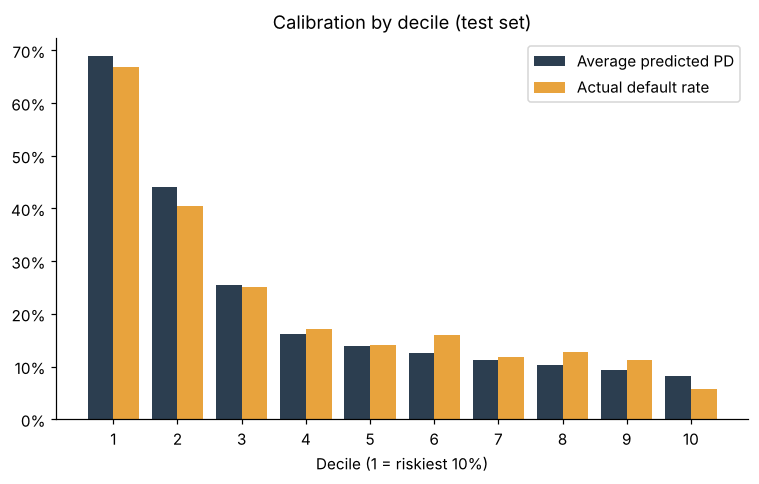

In [22]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(1, 11)
ax.bar(x - 0.2, deciles["avg_predicted_pd"], 0.4, color="#2C3E50", label="Average predicted PD")
ax.bar(x + 0.2, deciles["actual_default_rate"], 0.4, color="#E8A33D", label="Actual default rate")
ax.set_xticks(x); ax.set_xlabel("Decile (1 = riskiest 10%)"); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Calibration by decile (test set)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/03_calibration.png", dpi=120, bbox_inches="tight"); plt.show()

**Well calibrated where it matters.** In the riskiest four deciles, predicted and actual rates are within a few points of each other,
and the riskiest 30% of accounts hold about 60% of all defaults.
In the safer half, predicted PDs sit in a narrow 8–14% band and the actual rates bounce around that band:
most of those accounts are "current with no late payments", and four features can't separate them much further.
That is the model's main limitation, and the place a richer model would add value (Section 13).

## 11. Choosing a cut-off from business costs

The model gives a PD; the business needs a yes/no: **flag this account for early intervention or not?**

Two kinds of mistake have different costs:
- **Missed default** (false negative): the account defaults with no intervention, a credit loss.
- **False alarm** (false positive): a good customer gets an unnecessary call or limit review, an operating cost and some annoyance.

**Deriving the cut-off.** With a calibrated PD, flag an account when the expected cost of *not* flagging it is higher than the cost of flagging it:

$$PD \times C_{\text{missed}} > (1 - PD) \times C_{\text{false alarm}} \quad\Rightarrow\quad PD > \frac{C_{\text{false alarm}}}{C_{\text{false alarm}} + C_{\text{missed}}}$$

Assume a missed default costs **5 times** a false alarm (an illustrative assumption; the dashboard lets you change it).
Then the cut-off is 1 ÷ (1 + 5) = **16.7%**.

In [23]:
C_MISSED, C_FALSE_ALARM = 5, 1
threshold = C_FALSE_ALARM / (C_FALSE_ALARM + C_MISSED)
print(f"Cut-off = {C_FALSE_ALARM} / ({C_FALSE_ALARM} + {C_MISSED}) = {threshold:.4f}")

flag = pd_test >= threshold
tn, fp, fn, tp = confusion_matrix(y_test, flag).ravel()
print(f"\nFlagged {flag.mean():.1%} of accounts")
print(f"Defaulters caught (recall)        = {tp} / ({tp} + {fn}) = {tp / (tp + fn):.1%}")
print(f"Flagged accounts that default     = {tp} / ({tp} + {fp}) = {tp / (tp + fp):.1%}   (precision)")
print(f"Total cost = {C_MISSED} x {fn} missed + {C_FALSE_ALARM} x {fp} false alarms = {C_MISSED * fn + C_FALSE_ALARM * fp:,}")
print(f"Cost of flagging nobody = {C_MISSED} x {tp + fn} = {C_MISSED * (tp + fn):,}")

Cut-off = 1 / (1 + 5) = 0.1667

Flagged 31.9% of accounts
Defaulters caught (recall)        = 816 / (816 + 511) = 61.5%
Flagged accounts that default     = 816 / (816 + 1097) = 42.7%   (precision)
Total cost = 5 x 511 missed + 1 x 1097 false alarms = 3,652
Cost of flagging nobody = 5 x 1327 = 6,635


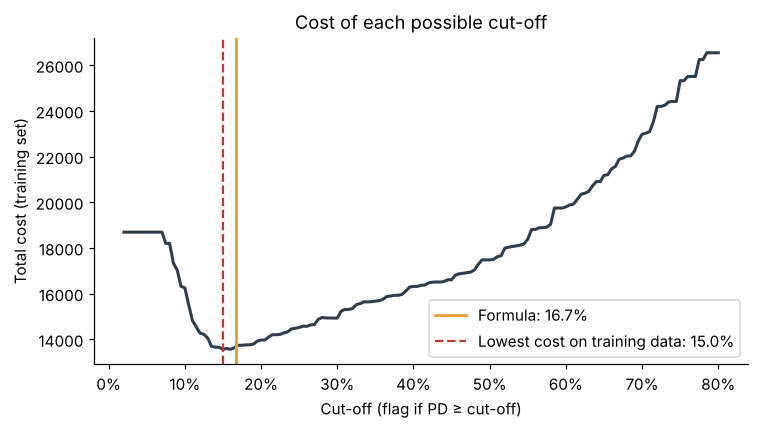

In [24]:
# Check the formula empirically: total cost for every possible cut-off on the TRAINING data
grid = np.linspace(0.02, 0.8, 157)
costs = [C_MISSED * ((pd_train < t) & (y_train.values == 1)).sum() + C_FALSE_ALARM * ((pd_train >= t) & (y_train.values == 0)).sum()
         for t in grid]
best = grid[int(np.argmin(costs))]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, costs, color="#2C3E50", lw=2)
ax.axvline(threshold, color="#E8A33D", lw=2, label=f"Formula: {threshold:.1%}")
ax.axvline(best, color="#C0392B", ls="--", label=f"Lowest cost on training data: {best:.1%}")
ax.set_xlabel("Cut-off (flag if PD ≥ cut-off)"); ax.set_ylabel("Total cost (training set)")
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.legend(); ax.set_title("Cost of each possible cut-off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/04_cost_cutoff.png", dpi=120, bbox_inches="tight"); plt.show()

The formula's cut-off lands close to the empirically cheapest one, which is what you'd expect from a calibrated model.
If the PDs were *not* calibrated (for example, the re-weighted model in Section 8), the formula would give the wrong answer.

## 12. The scorecard: turning PD into points

Risk teams usually work with **scores**, not raw probabilities. The industry-standard scaling:
- **600 points** = odds of 50 good : 1 bad
- **+20 points** doubles the odds ("points to double the odds", PDO)

**Step by step**
1. Factor = PDO ÷ ln(2) = 20 ÷ 0.6931 = **28.85** points per unit of log-odds
2. Offset = 600 − 28.85 × ln(50) = 600 − 28.85 × 3.912 = **487.1**
3. Score = Offset + Factor × ln(odds of good) = 487.1 + 28.85 × ln((1 − PD) ÷ PD)

**Points per bin.** Since log-odds of *default* = β₀ + Σ βⱼ × WoEⱼ, the score splits into one piece per feature:

$$\text{points}_{j} = -\text{Factor} \times \beta_j \times WoE_j + \frac{\text{Offset} - \text{Factor} \times \beta_0}{n}$$

where *n* = 4 features. Each account's score is simply the sum of its four points, which makes every score explainable line by line.

In [25]:
PDO, BASE_SCORE, BASE_ODDS = 20, 600, 50
FACTOR = PDO / np.log(2)
OFFSET = BASE_SCORE - FACTOR * np.log(BASE_ODDS)
print(f"Factor = {PDO} / ln(2) = {FACTOR:.4f}")
print(f"Offset = {BASE_SCORE} - {FACTOR:.4f} x ln({BASE_ODDS}) = {OFFSET:.4f}")

beta = scorecard.named_steps["model"].coef_[0]
alpha = scorecard.named_steps["model"].intercept_[0]
woe_tables = scorecard.named_steps["woe"].tables_
rows = []
for j, f in enumerate(FEATURES):
    for _, r in woe_tables[f].iterrows():
        rows.append({"feature": f, "bin": r["bin"], "woe": r["woe"],
                     "points": -FACTOR * beta[j] * r["woe"] + (OFFSET - FACTOR * alpha) / len(FEATURES)})
points_table = pd.DataFrame(rows)
points_table.round({"woe": 3, "points": 1})

Factor = 20 / ln(2) = 28.8539
Offset = 600 - 28.8539 x ln(50) = 487.1229


,feature,bin,woe,points
0,limit_bal,≤ NT$50K,-0.512,124.100
1,limit_bal,NT$50K–100K,-0.209,128.100
2,limit_bal,NT$100K–180K,0.131,132.500
3,limit_bal,NT$180K–270K,0.333,135.200
4,limit_bal,> NT$270K,0.635,139.100
5,pay_status_latest,No card use,0.669,142.400
6,pay_status_latest,Paid in full,0.353,136.900
7,pay_status_latest,Revolving (paid minimum),0.660,142.200
8,pay_status_latest,1 month late,-0.611,120.200
9,pay_status_latest,2 months late,-2.075,94.900


In [26]:
def to_score(p):
    return OFFSET + FACTOR * np.log((1 - p) / p)

# One test account, scored two ways: from its PD, and by adding up its points
acct = test.iloc[[0]]
p = scorecard.predict_proba(acct[FEATURES])[0, 1]
total = 0
for f in FEATURES:
    b = assign_bins(f, acct[f]).iloc[0]
    pts = points_table[(points_table["feature"] == f)].iloc[b]["points"]
    total += pts
    print(f"{f:22s} value {acct[f].iloc[0]:>10,.3f}  ->  bin '{BIN_LABELS[f][b]}'  ->  {pts:6.1f} points")
print(f"\nSum of points = {total:.1f}")
print(f"Score from PD = 487.1 + 28.85 x ln((1 - {p:.4f}) / {p:.4f}) = {to_score(p):.1f}")

limit_bal              value 50,000.000  ->  bin '≤ NT$50K'  ->   124.1 points
pay_status_latest      value     -1.000  ->  bin 'Paid in full'  ->   136.9 points
months_delinquent_6m   value      0.000  ->  bin '0'  ->   141.8 points
avg_utilization_6m     value      0.121  ->  bin '2%–13%'  ->   136.5 points

Sum of points = 539.4
Score from PD = 487.1 + 28.85 x ln((1 - 0.1405) / 0.1405) = 539.4


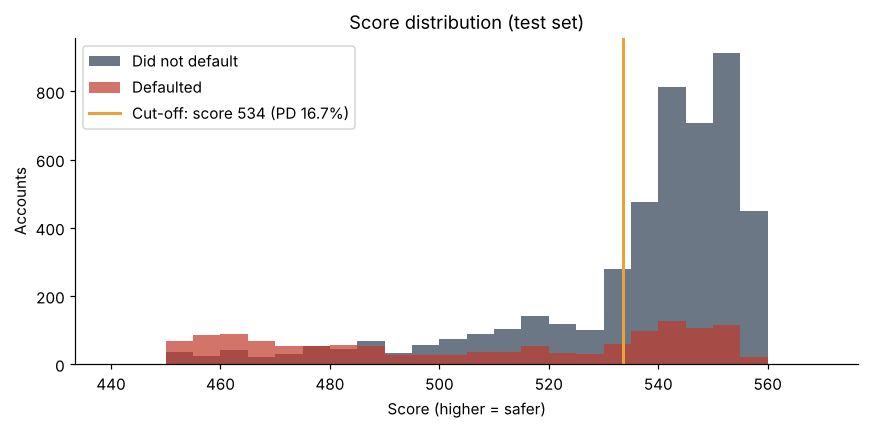

In [27]:
score_test = to_score(pd_test)
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(440, 575, 5)
ax.hist(score_test[y_test.values == 0], bins=bins, alpha=0.7, color="#2C3E50", label="Did not default")
ax.hist(score_test[y_test.values == 1], bins=bins, alpha=0.7, color="#C0392B", label="Defaulted")
ax.axvline(to_score(threshold), color="#E8A33D", lw=2, label=f"Cut-off: score {to_score(threshold):.0f} (PD {threshold:.1%})")
ax.set_xlabel("Score (higher = safer)"); ax.set_ylabel("Accounts"); ax.legend(); ax.set_title("Score distribution (test set)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/05_score_distribution.png", dpi=120, bbox_inches="tight"); plt.show()

Scores fall between roughly 450 and 560, below the 600 anchor, because this is a high-risk portfolio: the *average* account has odds of only about 3.5 : 1.
The scaling anchor is a convention; what matters is that 20 points always means twice the odds.

## 13. Challenger models

Model risk management expects a model to be compared with alternatives. Two challengers:
1. **Plain logistic regression** on the raw (standardised) features, without binning
2. **Gradient boosting** (`HistGradientBoostingClassifier`) on all 19 non-protected raw columns (limit, repayment statuses, bills, payments): a flexible "black box"

In [28]:
# Challenger 1: plain logistic regression on the same 4 features, standardised, no WoE
plain = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
plain_cv = cross_val_score(plain, train[FEATURES], y_train, cv=cv, scoring="roc_auc").mean()
plain.fit(train[FEATURES], y_train)

# Challenger 2: gradient boosting on every non-protected raw column
RAW_COLS = ["LIMIT_BAL"] + PAY_COLS + BILL_COLS + PAY_AMT_COLS
gbm = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
gbm_cv = cross_val_score(gbm, train[RAW_COLS], y_train, cv=cv, scoring="roc_auc").mean()
gbm.fit(train[RAW_COLS], y_train)

comparison = pd.DataFrame({
    "features": [4, 4, len(RAW_COLS)],
    "cv_auc": [cv_auc.mean(), plain_cv, gbm_cv],
    "test_auc": [auc, roc_auc_score(y_test, plain.predict_proba(test[FEATURES])[:, 1]),
                 roc_auc_score(y_test, gbm.predict_proba(test[RAW_COLS])[:, 1])],
    "explainable_as_points": ["Yes", "Partly", "No"],
}, index=["WoE scorecard (selected)", "Plain logistic regression", "Gradient boosting"])
comparison["test_gini"] = 2 * comparison["test_auc"] - 1
comparison

,features,cv_auc,test_auc,explainable_as_points,test_gini
WoE scorecard (selected),4,0.764,0.744,Yes,0.488
Plain logistic regression,4,0.742,0.719,Partly,0.438
Gradient boosting,19,0.780,0.775,No,0.551


**Conclusions**
- **WoE beats plain logistic regression** using the *same four features*, because the bins capture the non-linear patterns (the utilization U-shape, the unordered repayment categories).
- **Gradient boosting is better** by about 6 points of Gini. In a regulated setting, that gain has to be weighed against explainability:
  every scorecard decision can be traced to four points values, and adverse-action reasons ("your recent late payments lowered your score") follow directly.
- **Typical practice:** deploy the scorecard as the champion, and keep the gradient-boosting model as a *challenger* to monitor how much accuracy is being left on the table.

## 14. Fairness check

The protected attributes were never given to the model, but their columns are still in the test data, so outcomes can be compared across groups.
Two questions per group:
- **Calibration:** does the average predicted PD match the group's actual default rate? (If not, the model systematically over- or under-states that group's risk.)
- **Flag rate:** what share of the group would be flagged at the 16.7% cut-off?

In [29]:
t = test.assign(pd=pd_test, flagged=pd_test >= threshold)
t["sex"] = t["SEX"].map({1: "Male", 2: "Female"})
t["age_band"] = pd.cut(t["AGE"], [0, 29, 39, 49, 120], labels=["Under 30", "30–39", "40–49", "50+"])

def fairness(group_col):
    g = t.groupby(group_col, observed=True).agg(accounts=("pd", "size"), avg_predicted_pd=("pd", "mean"),
                                                 actual_default_rate=(TARGET, "mean"), flag_rate=("flagged", "mean"))
    g["pd_minus_actual"] = g["avg_predicted_pd"] - g["actual_default_rate"]
    return g

print(fairness("sex").round(3)); print(); print(fairness("age_band").round(3))

        accounts  avg_predicted_pd  actual_default_rate  flag_rate  \
sex                                                                  
Female      3598             0.216                0.213      0.315   
Male        2402             0.227                0.234      0.324   

        pd_minus_actual  
sex                      
Female            0.003  
Male             -0.007  

          accounts  avg_predicted_pd  actual_default_rate  flag_rate  \
age_band                                                               
Under 30      1912             0.239                0.223      0.347   
30–39         2198             0.206                0.206      0.299   
40–49         1341             0.213                0.233      0.305   
50+            549             0.230                0.246      0.332   

          pd_minus_actual  
age_band                   
Under 30            0.015  
30–39              -0.000  
40–49              -0.019  
50+                -0.016  


**Reading the result.** Within each group, predicted and actual default rates are within about 2 percentage points, and flag rates track the groups' actual risk.
The model slightly *under*-predicts risk for customers aged 40+ and slightly *over*-predicts it for those under 30.
The gaps are small, but in production this table would be part of every monitoring cycle, with agreed tolerances.

## 15. Monitoring: population stability index (PSI)

Once deployed, the population being scored drifts (economy, products, marketing). PSI measures how far the current score distribution has moved from the one the model was built on.

**Step by step**
1. Cut the *training* scores into 10 equal groups (deciles); each holds 10% of training accounts (the *expected* %).
2. Count the share of the *new* accounts that falls in each group (the *actual* %).
3. For each group: (actual% − expected%) × ln(actual% ÷ expected%). PSI is the sum.

| PSI | Meaning |
|---|---|
| < 0.10 | Stable |
| 0.10–0.25 | Some shift: investigate |
| > 0.25 | Significant shift: review or rebuild the model |

In [30]:
def psi_table(expected, actual, n_bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, n_bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = pd.Series(pd.cut(expected, edges)).value_counts(sort=False) / len(expected)
    a = pd.Series(pd.cut(actual, edges)).value_counts(sort=False).reindex(e.index) / len(actual)
    e, a = e.clip(lower=1e-6), a.clip(lower=1e-6)
    out = pd.DataFrame({"expected_pct": e.values, "actual_pct": a.values})
    out["psi"] = (out["actual_pct"] - out["expected_pct"]) * np.log(out["actual_pct"] / out["expected_pct"])
    return out

score_train = to_score(pd_train)
stable = psi_table(score_train, score_test)
print(f"PSI, training vs test scores = {stable['psi'].sum():.4f}  (stable, as expected: same population)")

def stressed_scores(util_multiplier, slip_share, seed=7):
    # Simulated deterioration: utilization rises by a multiplier, and a share of
    # 'current' customers (no use / paid in full / revolving) slip to 1 month late
    rng = np.random.default_rng(seed)
    s = test[FEATURES].copy()
    s["avg_utilization_6m"] *= util_multiplier
    slip = (s["pay_status_latest"] <= 0) & (rng.random(len(s)) < slip_share)
    s.loc[slip, "pay_status_latest"] = 1
    s.loc[slip, "months_delinquent_6m"] += 1
    return to_score(scorecard.predict_proba(s)[:, 1])

mild = psi_table(score_train, stressed_scores(1.3, 0.10))
severe = psi_table(score_train, stressed_scores(1.5, 0.25))
print(f"PSI, mild stress   (utilization +30%, 10% of current customers slip) = {mild['psi'].sum():.4f}")
print(f"PSI, severe stress (utilization +50%, 25% of current customers slip) = {severe['psi'].sum():.4f}")
severe.round(4)

PSI, training vs test scores = 0.0021  (stable, as expected: same population)
PSI, mild stress   (utilization +30%, 10% of current customers slip) = 0.0258
PSI, severe stress (utilization +50%, 25% of current customers slip) = 0.1551


,expected_pct,actual_pct,psi
0,0.100,0.112,0.001
1,0.105,0.201,0.061
2,0.095,0.165,0.039
3,0.124,0.099,0.006
4,0.095,0.071,0.006
5,0.086,0.071,0.003
6,0.112,0.079,0.011
7,0.097,0.072,0.007
8,0.106,0.074,0.011
9,0.081,0.056,0.009


**Two lessons.** The severe scenario pushes PSI past the 0.10 "investigate" level, so monitoring would flag a sharply deteriorating population
before the defaults arrived. But the mild scenario stays under 0.10 even though it raises the average PD: PSI only notices *large* shifts.
That is why PSI is tracked alongside the actual default rate and calibration, and on each input feature too, so the cause of a shift can be pinpointed.

## 16. Limitations and model ownership

**Limitations**
- **Data:** one bank, Taiwan, 2005, during a card-debt crisis; amounts in NT\$. The method transfers, the numbers don't.
- **Horizon:** predicts default *next month*. Regulatory PD models (IFRS 9 / Basel) use 12-month and lifetime horizons.
- **Behavioural, not application:** it scores existing customers; it can't be used to approve new applicants, who have no repayment history.
- **Undocumented codes:** the meaning of repayment codes −2 and 0 is an assumption that would need confirming with the data owner.
- **Limited separation among clean accounts:** most "current" customers get PDs in a narrow 8–14% band (Section 10).

**If I owned this model in production**
| Area | Practice |
|---|---|
| Documentation | Model card: purpose, data, exclusions and why, assumptions, performance, limitations, intended and prohibited uses |
| Validation | Independent review of binning, WoE, coefficients, calibration and the fairness analysis before use |
| Monitoring | Monthly: score PSI and feature PSI; quarterly: AUC/Gini, KS and decile calibration on matured outcomes; fairness table each cycle |
| Triggers | PSI > 0.25, Gini falling more than 5 points below development, or calibration drift beyond an agreed tolerance → review or rebuild |
| Challenger | Keep the gradient-boosting model running in parallel to track the accuracy gap |
| Governance | Version control, change log, alignment with the bank's model risk management policy (e.g. OSFI Guideline E-23 in Canada) |

**Code reuse:** the final model is also implemented in `src/credit_model.py`, which powers the dashboard (`app.py`).
The automated tests in `tests/` confirm it reproduces this notebook's numbers.